# Explaining a Credit Risk Model with SHAP and LIME

In this practice you will train a black-box model to predict credit risk, then explain it in two ways: with SHAP, for both global and local explanations, and with LIME, for a local explanation of one customer.

Everything here uses only what Lesson 8 covers: black-box and white-box models, global and local interpretability, and the LIME and SHAP methods.

## Background

A bank wants to predict which customers will be a "bad" credit risk. A random forest gives good accuracy, but it is a black-box model: loan officers and customers cannot see why it makes a decision. Explainable AI (XAI) methods make those decisions understandable.

This practice uses **Credit Scoring Data.csv**, the dataset from Lesson 7.

**Before you start:** install the two XAI libraries with `pip install shap lime`.

## Data Description

| Column Name | Description |
|---|---|
| custid | Unique customer identifier |
| debtinc | Debt to income ratio |
| creddebt | Credit card debt amount |
| othdebt | Other outstanding debts |
| preloan | Previous loan history indicator |
| veh | Vehicle ownership status |
| house | House ownership status |
| selfemp | Self-employed indicator |
| account | Bank account indicator |
| deposit | Deposit holding indicator |
| emp | Length of employment |
| address | Years at current address |
| branch | Bank branch code |
| ref | Reference availability indicator |
| age | Age group code |
| gender | Gender code |
| ms | Marital status code |
| child | Children / dependent indicator |
| zone | Residential zone / region code |
| bad | **Target variable:** 1 = bad credit risk, 0 = good |

## 1. Load the Data and Train a Black-Box Model

We drop `custid`, which is only an identifier, and `gender`, a protected characteristic that should not drive credit decisions. Age is also a sensitive characteristic; it is kept here, but in practice its use would need a fairness review, which is one of the jobs XAI supports. Then we train a random forest, one of the lesson's examples of a black-box model.

In [1]:
import warnings
warnings.filterwarnings("ignore")   # keep the output readable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

credit = pd.read_csv("Credit Scoring Data.csv")
X = credit.drop(columns=["custid", "gender", "bad"])
y = credit["bad"]

print("Rows:", len(credit), "| Share of bad risks:", round(y.mean(), 3))

Rows: 6990 | Share of bad risks: 0.132


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=200, max_depth=6,
                               class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print("Test ROC-AUC:", round(auc, 3))

Test ROC-AUC: 0.792


The model ranks risk well, but on its own it only gives a score. It cannot say *why*.

## 2. Choose One Customer to Explain

We pick the test customer with the highest predicted risk.

In [3]:
probs = model.predict_proba(X_test)[:, 1]
idx = int(np.argmax(probs))
customer = X_test.iloc[[idx]]

print("Risk score for this customer:", round(probs[idx], 3))
customer

Risk score for this customer: 0.796


,debtinc,creddebt,othdebt,preloan,veh,house,selfemp,account,deposit,emp,address,branch,ref,age,ms,child,zone
510,19.46,5.07,2.47,1,2,2,2,2,1,4,2,1,1,3,1,1,13


## 3. SHAP: Base Value and Feature Contributions

SHAP treats each feature as a player in a game and shares out the prediction fairly, using Shapley values. The lesson's steps are: compute a **base value** (the average prediction), measure each feature's contribution, and check that **base value + sum of SHAP values = final prediction**.

In [4]:
import shap

explainer = shap.TreeExplainer(model)
explanation = explainer(X_test)

# Keep the explanations for class 1 (bad risk)
shap_bad = explanation[:, :, 1]

base_value = shap_bad.base_values[idx]
contributions = pd.Series(shap_bad.values[idx], index=X.columns).sort_values(key=abs, ascending=False)

print("Base value (average prediction):", round(base_value, 3))
print("\nTop five contributions for this customer:")
print(contributions.head().round(3))

Base value (average prediction): 0.5

Top five contributions for this customer:
emp         0.086
debtinc     0.080
creddebt    0.060
address     0.040
othdebt     0.008
dtype: float64


In [5]:
print("Base value + sum of SHAP values:", round(base_value + contributions.sum(), 3))
print("Model's risk score:             ", round(probs[idx], 3))

Base value + sum of SHAP values: 0.796
Model's risk score:              0.796


The two numbers match: SHAP's contributions add up exactly to the model's prediction. Positive values push the prediction towards bad risk; negative values push it away.

The base value is 0.5 rather than the 13% share of bad risks because the model was trained with balanced class weights, which give the two classes equal weight. For the same reason, the model's outputs are **risk scores** for ranking customers, not real-world probabilities.

## 4. SHAP Local Explanation: Waterfall Plot

The waterfall plot shows how this customer's prediction builds up from the base value, one feature at a time. This is **local interpretability**: it explains one decision.

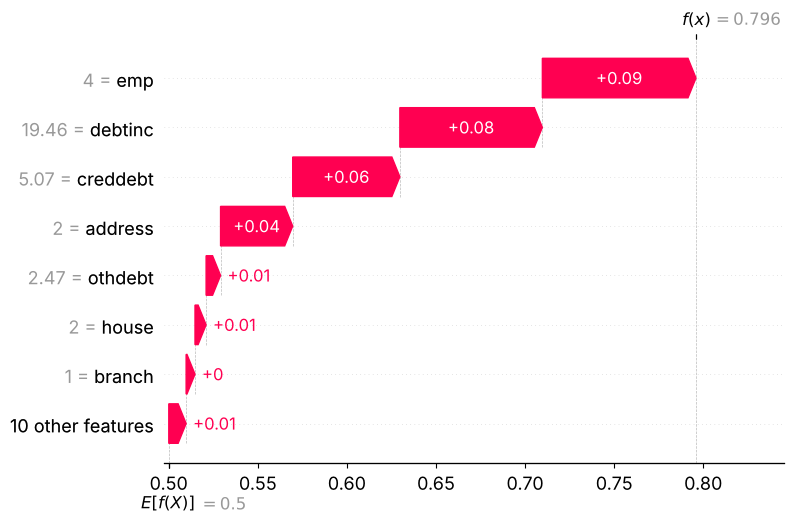

In [6]:
shap.plots.waterfall(shap_bad[idx], max_display=8)

## 5. SHAP Global Explanation: Summary Plot

Averaging the size of the SHAP values across all test customers shows which features matter most to the model overall. This is **global interpretability**.

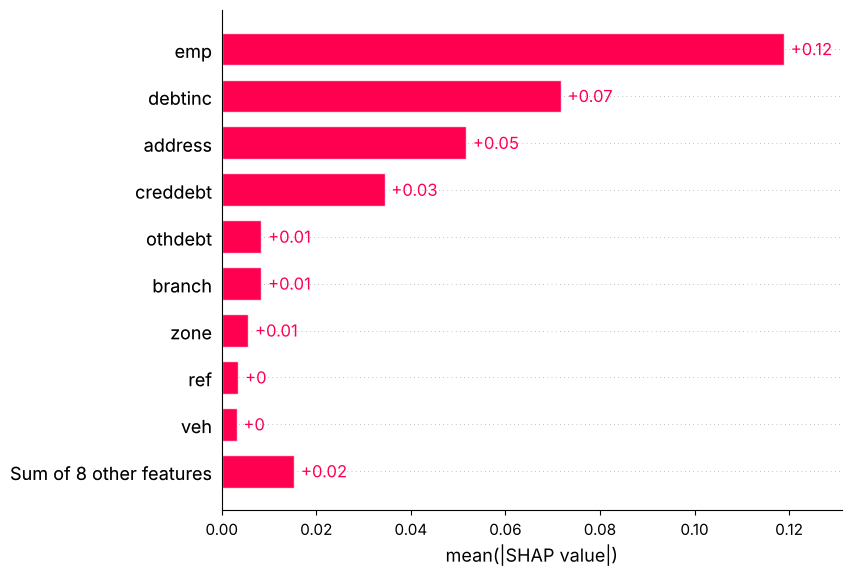

In [7]:
shap.plots.bar(shap_bad, max_display=10)

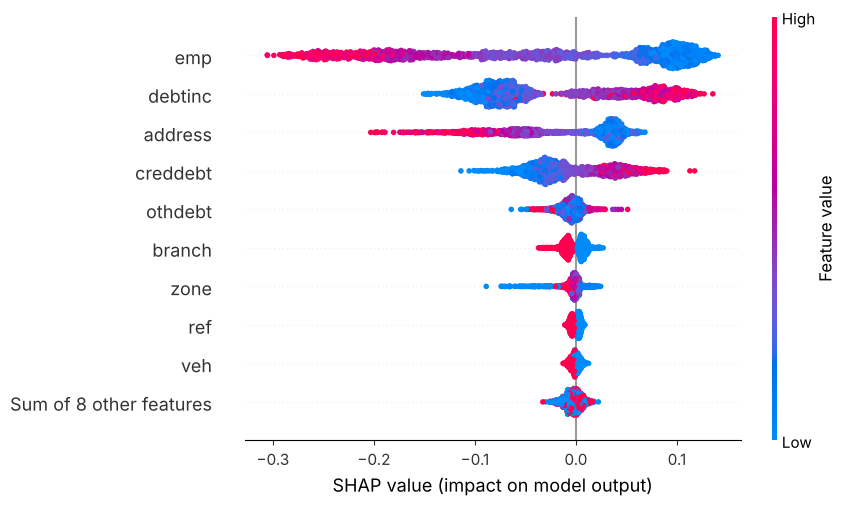

In [8]:
shap.plots.beeswarm(shap_bad, max_display=10)

In the beeswarm plot, each dot is one customer. Its colour shows the feature's value (red is high, blue is low), and its position shows whether that value pushed the prediction towards bad risk (right) or away from it (left).

## 6. LIME: A Local Surrogate Model

LIME explains one prediction by generating synthetic data around the customer, running the model on it, and fitting a simple linear model locally. It is **model-agnostic**: it only needs the model's prediction function.

In [9]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=list(X.columns),
    class_names=["good", "bad"],
    mode="classification",
    random_state=1)

lime_exp = lime_explainer.explain_instance(
    customer.to_numpy()[0], model.predict_proba, num_features=5)

pd.DataFrame(lime_exp.as_list(), columns=["condition", "weight towards bad risk"]).round(3)

,condition,weight towards bad risk
0,debtinc > 16.69,0.136
1,3.00 < emp <= 8.00,0.116
2,address <= 3.00,0.083
3,creddebt > 3.64,0.063
4,branch <= 1.00,0.019


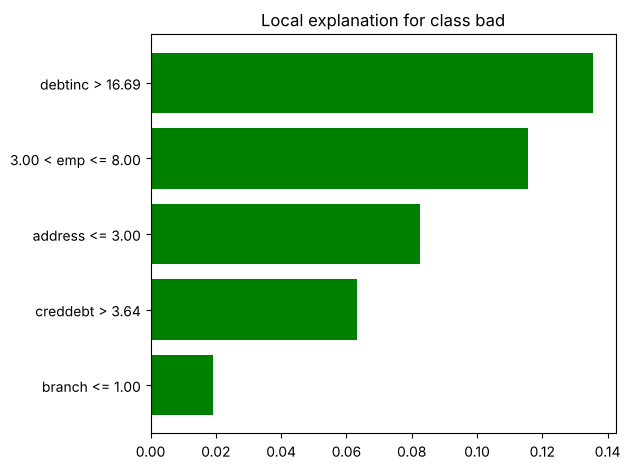

In [10]:
lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

## 7. Compare the Stability of LIME and SHAP

The lesson notes that LIME's explanations can vary between runs, because the synthetic data is random. We explain the same customer with three different random seeds.

In [11]:
for seed in [1, 2, 3]:
    explainer_seed = LimeTabularExplainer(
        X_train.to_numpy(), feature_names=list(X.columns),
        class_names=["good", "bad"], mode="classification", random_state=seed)
    exp = explainer_seed.explain_instance(customer.to_numpy()[0], model.predict_proba, num_features=5)
    print(f"Seed {seed}:", [(c, round(w, 3)) for c, w in exp.as_list()])

Seed 1: [('debtinc > 16.69', 0.136), ('3.00 < emp <= 8.00', 0.116), ('address <= 3.00', 0.083), ('creddebt > 3.64', 0.063), ('branch <= 1.00', 0.019)]


Seed 2: [('debtinc > 16.69', 0.145), ('3.00 < emp <= 8.00', 0.115), ('creddebt > 3.64', 0.07), ('address <= 3.00', 0.068), ('1.00 < veh <= 2.00', -0.012)]


Seed 3: [('debtinc > 16.69', 0.144), ('3.00 < emp <= 8.00', 0.112), ('address <= 3.00', 0.073), ('creddebt > 3.64', 0.071), ('2.00 < age <= 3.00', 0.016)]


In [12]:
shap_again = explainer(X_test.iloc[[idx]])[:, :, 1]
print("SHAP values, second run, match the first:",
      np.allclose(shap_again.values[0], shap_bad.values[idx]))

SHAP values, second run, match the first: True


The LIME weights change from seed to seed, while the SHAP values for a tree model are the same every time. This matches the lesson's comparison: LIME is fast and local, while SHAP is more stable and gives both local and global views.

## 8. Turn the Explanation into Plain Language

An explanation is only useful if a person can act on it. Here we turn the top SHAP contributions into a short reason statement, like the lesson's loan example.

In [13]:
top = contributions.head(3)
reasons = [f"{feature} = {customer[feature].iloc[0]} ({'raises' if value > 0 else 'lowers'} risk)"
           for feature, value in top.items()]

print(f"Risk score {probs[idx]:.2f} (high), mainly because of:")
for r in reasons:
    print(" -", r)

Risk score 0.80 (high), mainly because of:
 - emp = 4 (raises risk)
 - debtinc = 19.46 (raises risk)
 - creddebt = 5.07 (raises risk)


## Summary

- A random forest is a black-box model: accurate, but its decisions are not directly understandable.
- SHAP shares each prediction among the features; the base value plus the SHAP values equals the prediction.
- SHAP gives local explanations (waterfall) and global explanations (bar and beeswarm plots).
- LIME fits a simple local model around one prediction; its results can vary between runs.
- Explanations should be turned into plain-language reasons that a customer or loan officer can understand.